In [ ]:
#Code with the topic : T-SNE

#Objective:

#Visualize high-dimensional student data in two dimensions
#using t-SNE to identify possible class clusters.

#Technologies:

#Pandas
#Matplotlib
#Scikit learn
#Python
#Visual Studio Code
#Jupyter Notebook

#Method used:

#T-SNE

In [3]:
#We import the libraries

import pandas as pd
from sklearn.manifold import TSNE
from sklearn.preprocessing  import StandardScaler
import matplotlib.pyplot as plt


In [4]:
#Load the dataset 

data = pd.read_csv("T-SNE.csv")

In [5]:
#Visualization

data.head()

,Age,Study_Hours,Attendance,Average_Grade,Participation,Class
0,18,5,90,85,8,A
1,19,6,95,88,9,A
2,20,4,80,75,7,B
3,21,3,70,68,6,B
4,22,7,98,92,10,A


In [6]:
data.describe()

,Age,Study_Hours,Attendance,Average_Grade,Participation
count,20.000000,20.000000,20.0000,20.000000,20.000000
mean,20.000000,4.650000,81.9000,77.850000,7.250000
std,1.450953,2.207046,13.7416,13.689316,2.074279
min,18.000000,1.000000,55.0000,50.000000,3.000000
25%,19.000000,3.000000,71.5000,68.750000,6.000000
50%,20.000000,4.500000,82.5000,78.000000,7.000000
75%,21.000000,6.250000,94.2500,88.500000,9.000000
max,22.000000,8.000000,99.0000,97.000000,10.000000


In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Age            20 non-null     int64 
 1   Study_Hours    20 non-null     int64 
 2   Attendance     20 non-null     int64 
 3   Average_Grade  20 non-null     int64 
 4   Participation  20 non-null     int64 
 5   Class          20 non-null     object
dtypes: int64(5), object(1)
memory usage: 1.1+ KB


In [8]:
#Separate features and labels

X = data.drop("Class", axis = 1)
y = data["Class"]

In [ ]:
#Stadardize the data 

scaler = StandardScaler()
x_scaled = scaler.fit_transform(X)

In [11]:
#Configure the t - SNE model

tsne = TSNE(
    n_components=2,
    perplexity=10,
    random_state=42
)

In [12]:
#Apply t-SNE

X_tsne = tsne.fit_transform(x_scaled)

In [13]:
#Store the transformed data

result = pd.DataFrame({
    "TSNE_1": X_tsne[:,0],
    "TSNE_2": X_tsne[:,1],
    "Class":y
})

print("\n Transformed data:")
print(result.head())




 Transformed data:
     TSNE_1     TSNE_2 Class
0  0.455845  -2.942139     A
1  2.943958   0.990863     A
2 -4.424590  -8.407533     B
3 -9.384744 -10.571702     B
4 -4.874671   6.823291     A


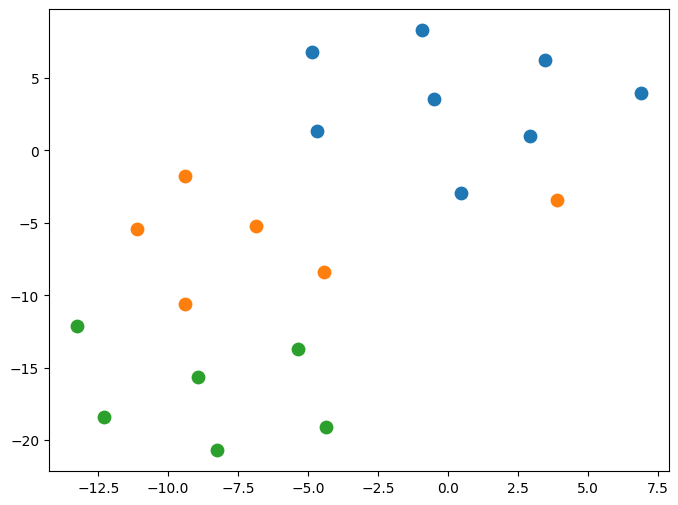

In [14]:
#Visualize the results

plt.figure(figsize=(8,6))

#Plot each class with a different color

for label in result["Class"].unique():
    subset = result[result["Class"] == label]


    plt.scatter(
        subset["TSNE_1"],
        subset["TSNE_2"],
        label=label,
        s=80
    )
    

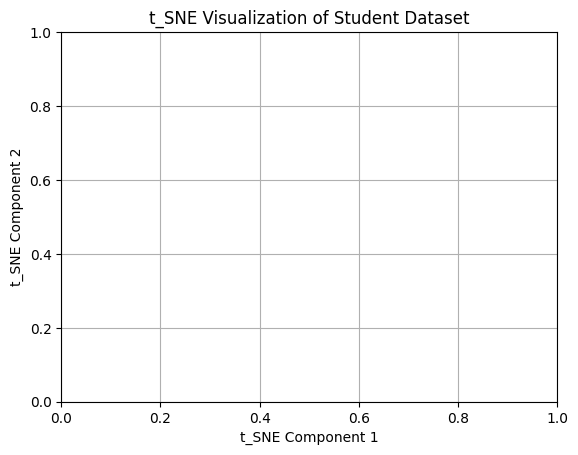

In [15]:
#Customize the plot 

plt.title("t_SNE Visualization of Student Dataset")
plt.xlabel("t_SNE Component 1")
plt.ylabel("t_SNE Component 2")
plt.grid(True)

#Display the plot
plt.show()